# 01 — Commodity Price Data & Feature EDA

**Goal:** Load the commodity price panel, inspect distributions, compute price features, and explore the target variables (forward returns).

This notebook corresponds to **Phase 2** of the research pipeline.

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from src.config import DATA_PROCESSED_DIR, ASSETS

sns.set_theme(style="whitegrid", palette="tab10")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (14, 5)

## 1. Load panel

In [2]:
df = pd.read_parquet(DATA_PROCESSED_DIR / "signal_dataset.parquet")
df["date"] = pd.to_datetime(df["date"])

print(f"Shape: {df.shape}")
print(f"Tickers: {sorted(df['ticker'].unique())}")
print(f"Date range: {df['date'].min().date()} → {df['date'].max().date()}")
df.head(3)

Shape: (31430, 24)
Tickers: ['CORN', 'DBA', 'GLD', 'SOYB', 'UNG', 'USO', 'WEAT']
Date range: 2005-01-03 → 2026-05-05


,date,ticker,close,asset,return_1d,return_5d,return_20d,volatility_20d,volatility_60d,momentum_20d,...,realized_kurtosis,future_return_1d,future_direction_1d,future_return_5d,future_direction_5d,future_return_10d,future_direction_10d,future_return_20d,future_direction_20d,cs_rank
0,2010-06-09,CORN,25.150000,corn,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.012326,1.0,0.046521,1.0,0.015507,1.0,0.081511,1.0,0.8
1,2010-06-10,CORN,25.459999,corn,0.012326,NaN,NaN,NaN,NaN,NaN,...,NaN,0.012962,1.0,0.024352,1.0,-0.006677,0.0,0.064808,1.0,0.4
2,2010-06-11,CORN,25.790001,corn,0.012962,NaN,NaN,NaN,NaN,NaN,...,NaN,0.012408,1.0,0.023265,1.0,-0.034897,0.0,0.038775,1.0,0.2


In [3]:
print("Missing values per column:")
df.isnull().mean().sort_values(ascending=False).head(15)

Missing values per column:


momentum_60d         0.013363
volatility_60d       0.013363
drawdown_60d         0.013140
return_20d           0.004454
momentum_20d         0.004454
volatility_20d       0.004454
realized_skewness    0.004454
trend_strength       0.004454
realized_kurtosis    0.004454
future_return_20d    0.004454
future_return_10d    0.002227
cs_rank              0.001114
future_return_5d     0.001114
return_5d            0.001114
return_1d            0.000223
dtype: float64

## 2. Normalized price levels

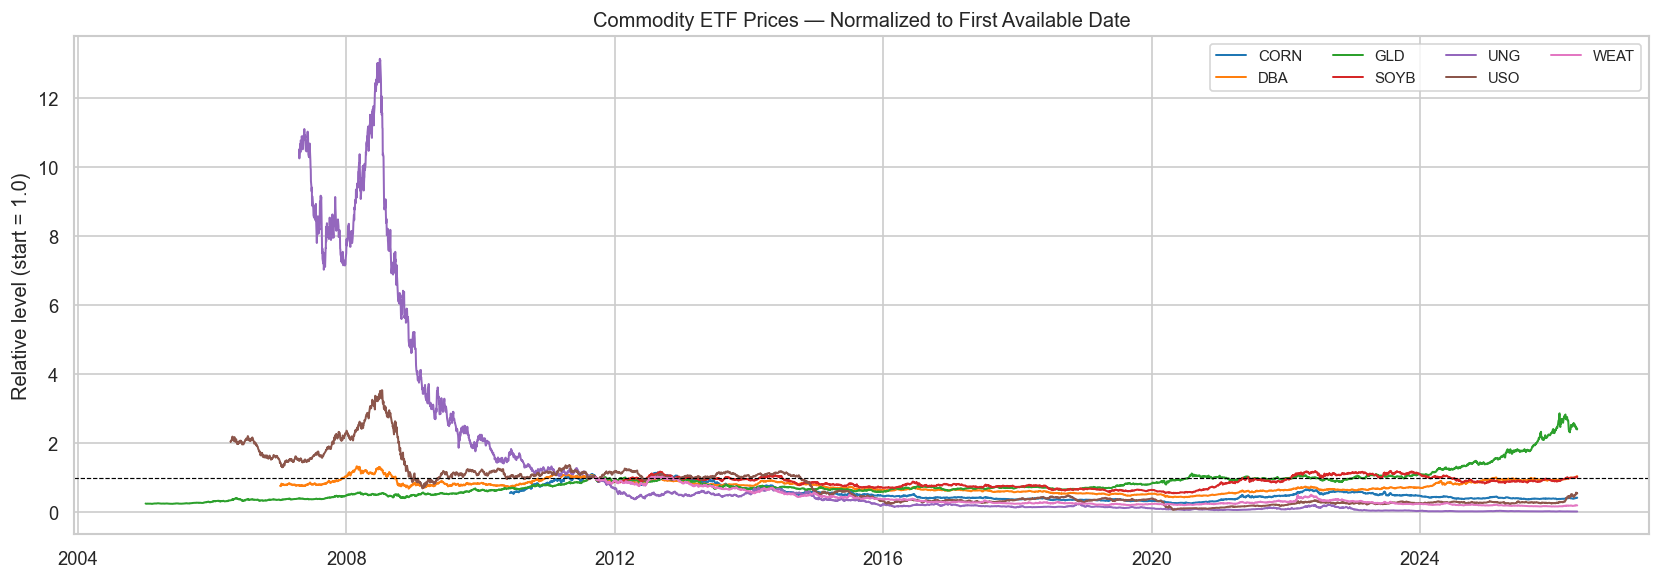

In [4]:
pivot = df.pivot_table(index="date", columns="ticker", values="close")
normalized = pivot / pivot.dropna().iloc[0]

fig, ax = plt.subplots()
for col in normalized.columns:
    ax.plot(normalized.index, normalized[col], label=col, lw=1.2)
ax.axhline(1, color="black", lw=0.7, ls="--")
ax.set_title("Commodity ETF Prices — Normalized to First Available Date")
ax.set_ylabel("Relative level (start = 1.0)")
ax.legend(ncol=4, fontsize=9)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout()
plt.savefig("../reports/figures/commodity_returns.png", dpi=150)
plt.show()

## 3. Daily return distributions

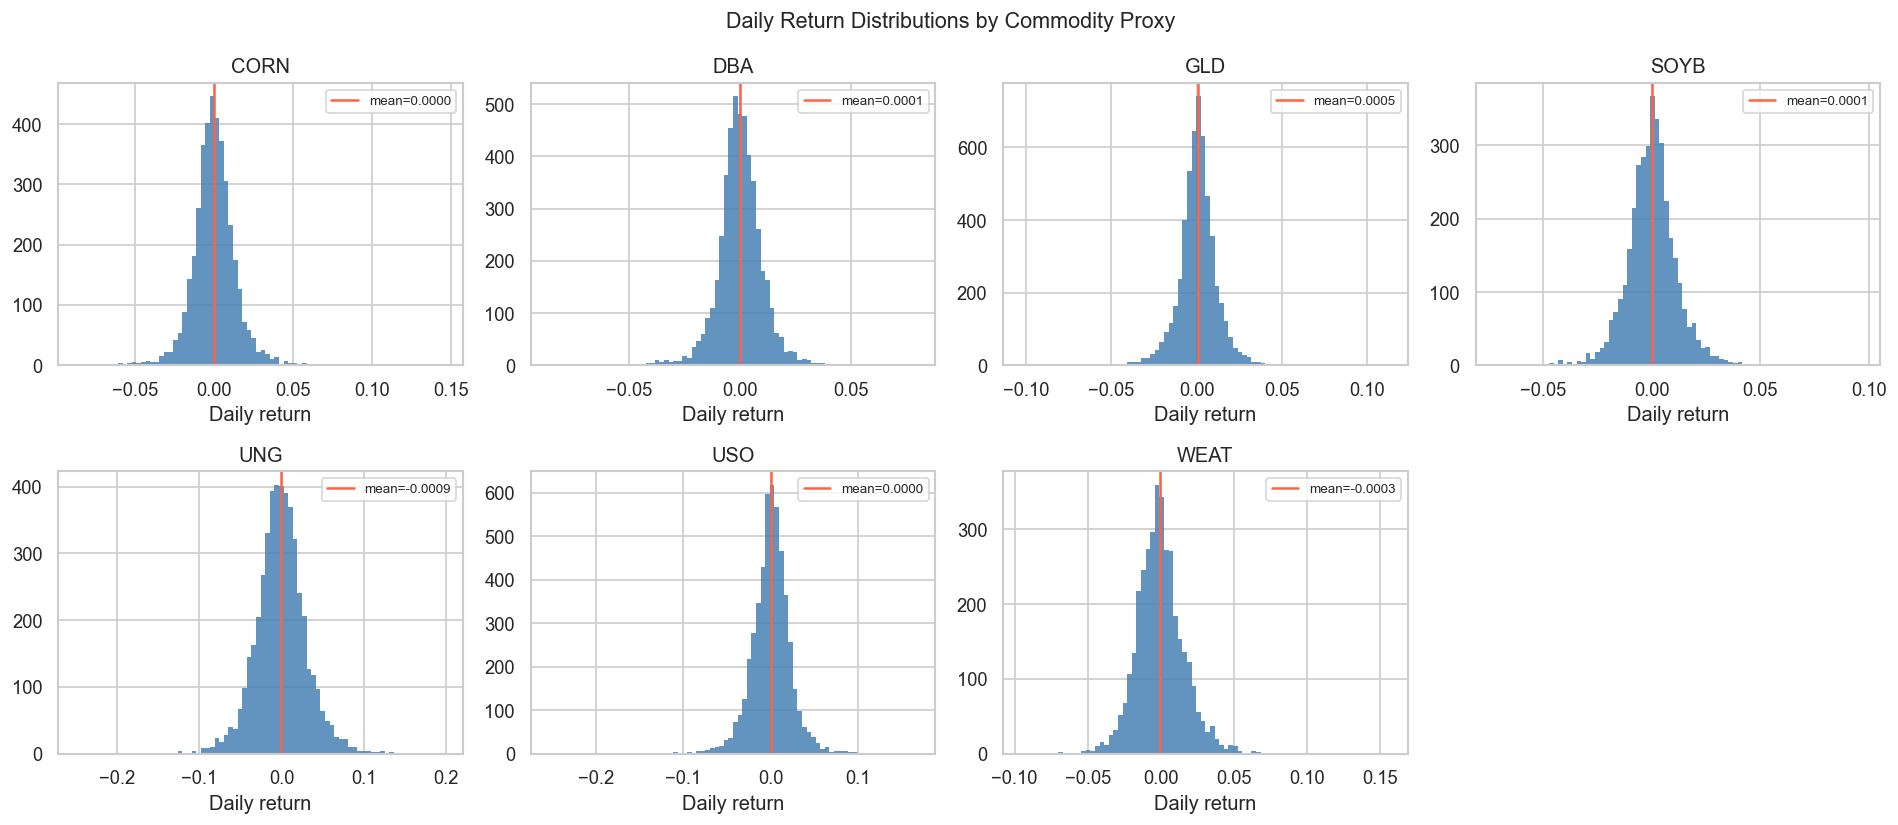

In [5]:
tickers = sorted(df["ticker"].unique())
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharey=False)
axes = axes.flatten()

for i, tkr in enumerate(tickers):
    sub = df[df["ticker"] == tkr]["return_1d"].dropna()
    ax = axes[i]
    ax.hist(sub, bins=80, color="steelblue", edgecolor="none", alpha=0.85)
    ax.axvline(sub.mean(), color="tomato", lw=1.5, label=f"mean={sub.mean():.4f}")
    ax.set_title(tkr)
    ax.set_xlabel("Daily return")
    ax.legend(fontsize=8)

for j in range(len(tickers), len(axes)):
    axes[j].set_visible(False)

fig.suptitle("Daily Return Distributions by Commodity Proxy", fontsize=13)
plt.tight_layout()
plt.show()

## 4. Return summary statistics

In [6]:
stats = (
    df.groupby("ticker")["return_1d"]
    .agg(
        n="count",
        mean=lambda x: x.mean(),
        std=lambda x: x.std(),
        skew=lambda x: x.skew(),
        kurt=lambda x: x.kurt(),
        ann_vol=lambda x: x.std() * np.sqrt(252),
        ann_ret=lambda x: x.mean() * 252,
        sharpe=lambda x: x.mean() / x.std() * np.sqrt(252) if x.std() > 0 else np.nan,
    )
    .round(4)
)
stats

,n,mean,std,skew,kurt,ann_vol,ann_ret,sharpe
ticker,,,,,,,,
CORN,4000,0.0000,0.0138,0.4229,6.4617,0.2185,0.0059,0.0268
DBA,4862,0.0001,0.0105,-0.1679,6.1268,0.1669,0.0300,0.1798
GLD,5367,0.0005,0.0114,-0.3093,6.7067,0.1813,0.1233,0.6799
SOYB,3677,0.0001,0.0115,0.0276,3.8783,0.1821,0.0180,0.0986
UNG,4792,-0.0009,0.0311,0.0969,3.2145,0.4933,-0.2152,-0.4363
USO,5048,0.0000,0.0233,-0.5608,9.5329,0.3692,0.0027,0.0073
WEAT,3677,-0.0003,0.0166,0.6256,4.7184,0.2641,-0.0779,-0.2952


## 5. Rolling volatility — volatility regimes

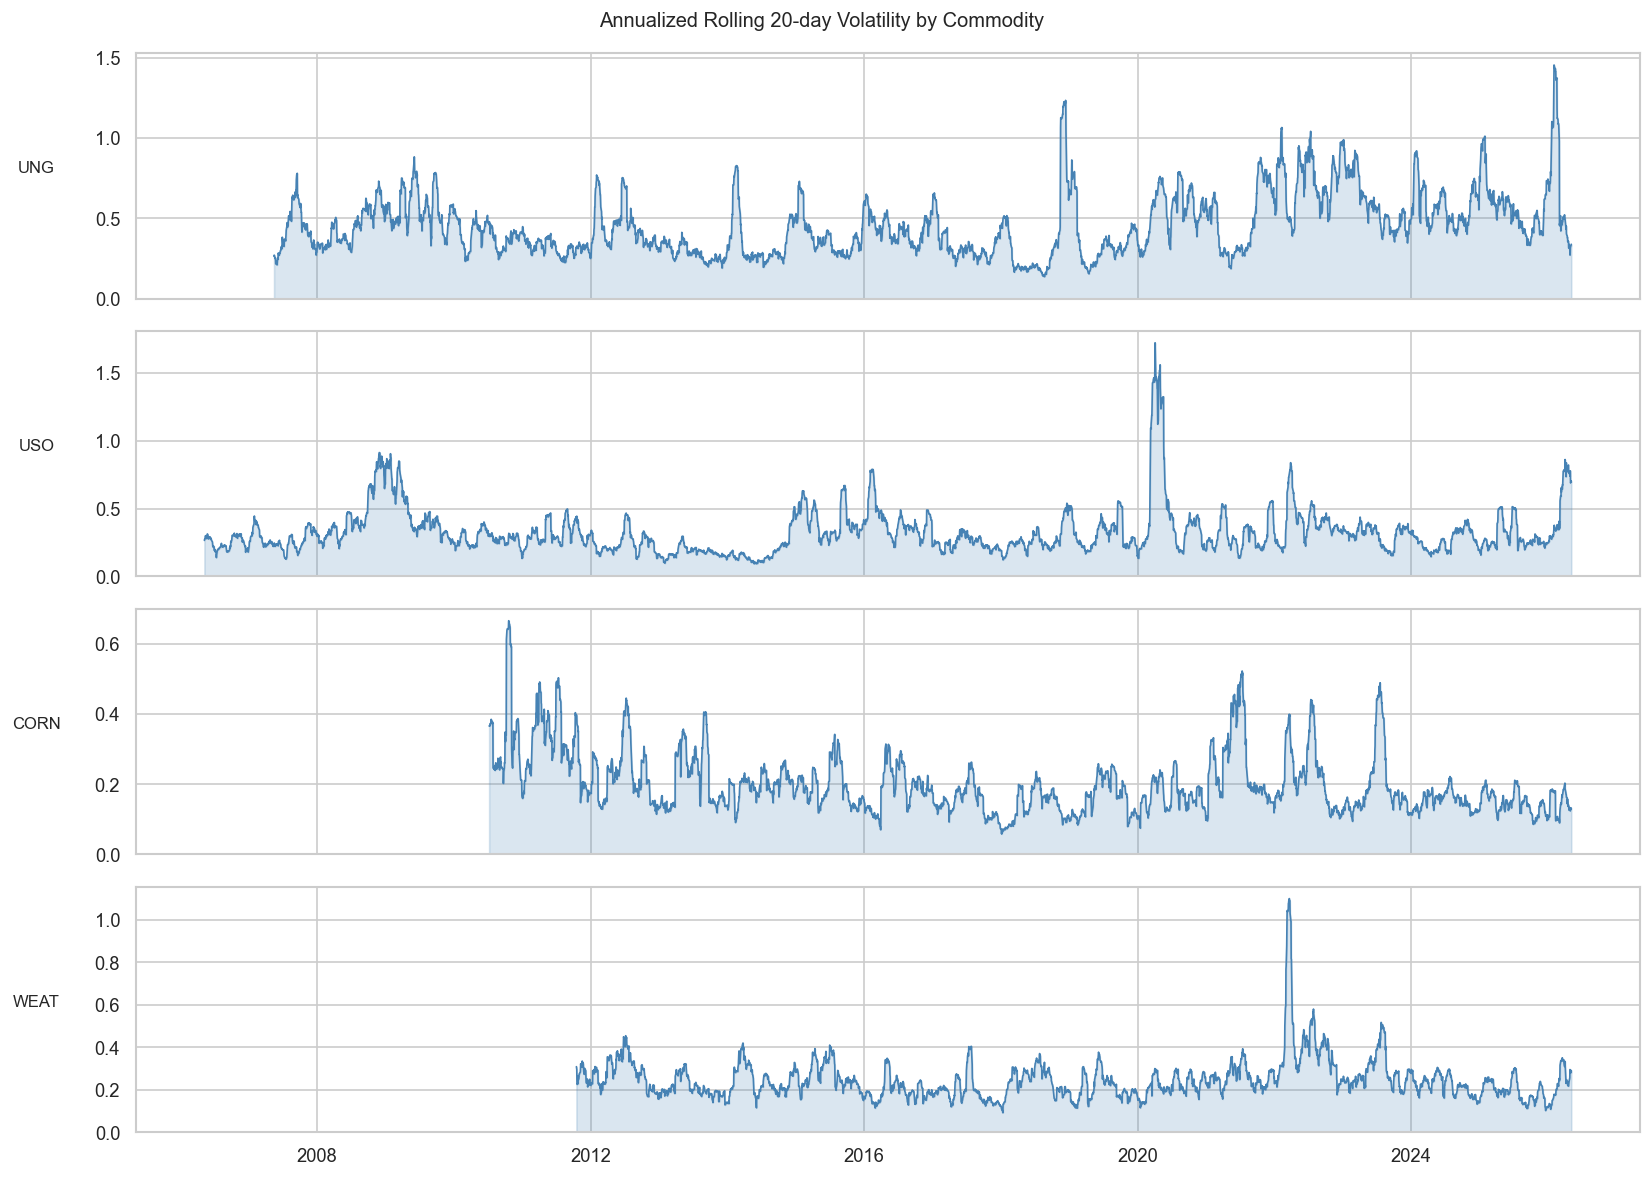

In [7]:
focus = ["UNG", "USO", "CORN", "WEAT"]
fig, axes = plt.subplots(len(focus), 1, figsize=(14, 10), sharex=True)

for ax, tkr in zip(axes, focus):
    sub = df[df["ticker"] == tkr].sort_values("date")
    ax.plot(sub["date"], sub["volatility_20d"] * np.sqrt(252), lw=1, color="steelblue")
    ax.fill_between(sub["date"], sub["volatility_20d"] * np.sqrt(252), alpha=0.2, color="steelblue")
    ax.set_ylabel(tkr, rotation=0, labelpad=35, fontsize=10)
    ax.set_ylim(bottom=0)

axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.suptitle("Annualized Rolling 20-day Volatility by Commodity", fontsize=12)
plt.tight_layout()
plt.show()

## 6. Return correlations (cross-asset)

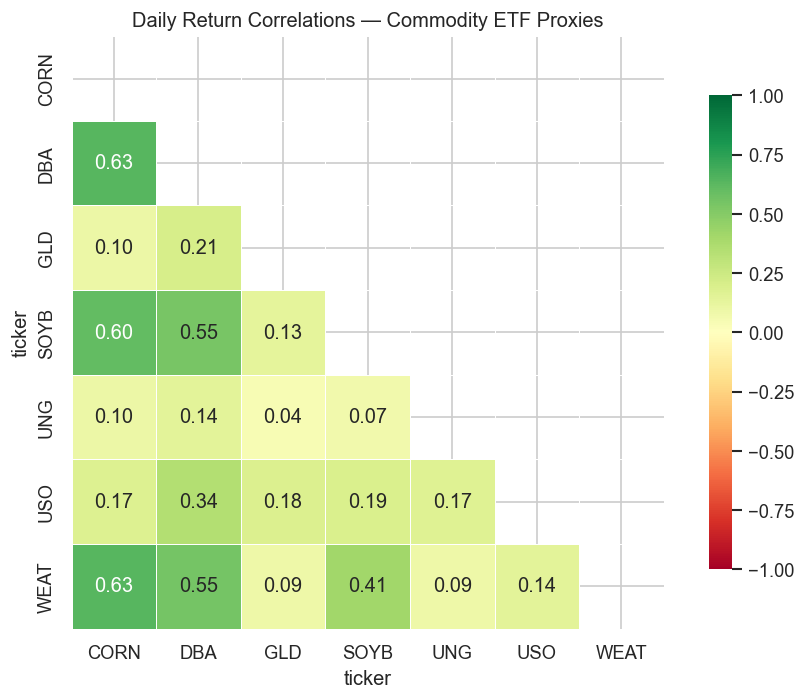

In [8]:
ret_pivot = df.pivot_table(index="date", columns="ticker", values="return_1d")
corr = ret_pivot.corr()

fig, ax = plt.subplots(figsize=(8, 6))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr, mask=mask, annot=True, fmt=".2f", cmap="RdYlGn",
    center=0, vmin=-1, vmax=1, ax=ax, square=True,
    linewidths=0.5, cbar_kws={"shrink": 0.8}
)
ax.set_title("Daily Return Correlations — Commodity ETF Proxies")
plt.tight_layout()
plt.show()

## 7. Target variable: 5-day forward return distribution

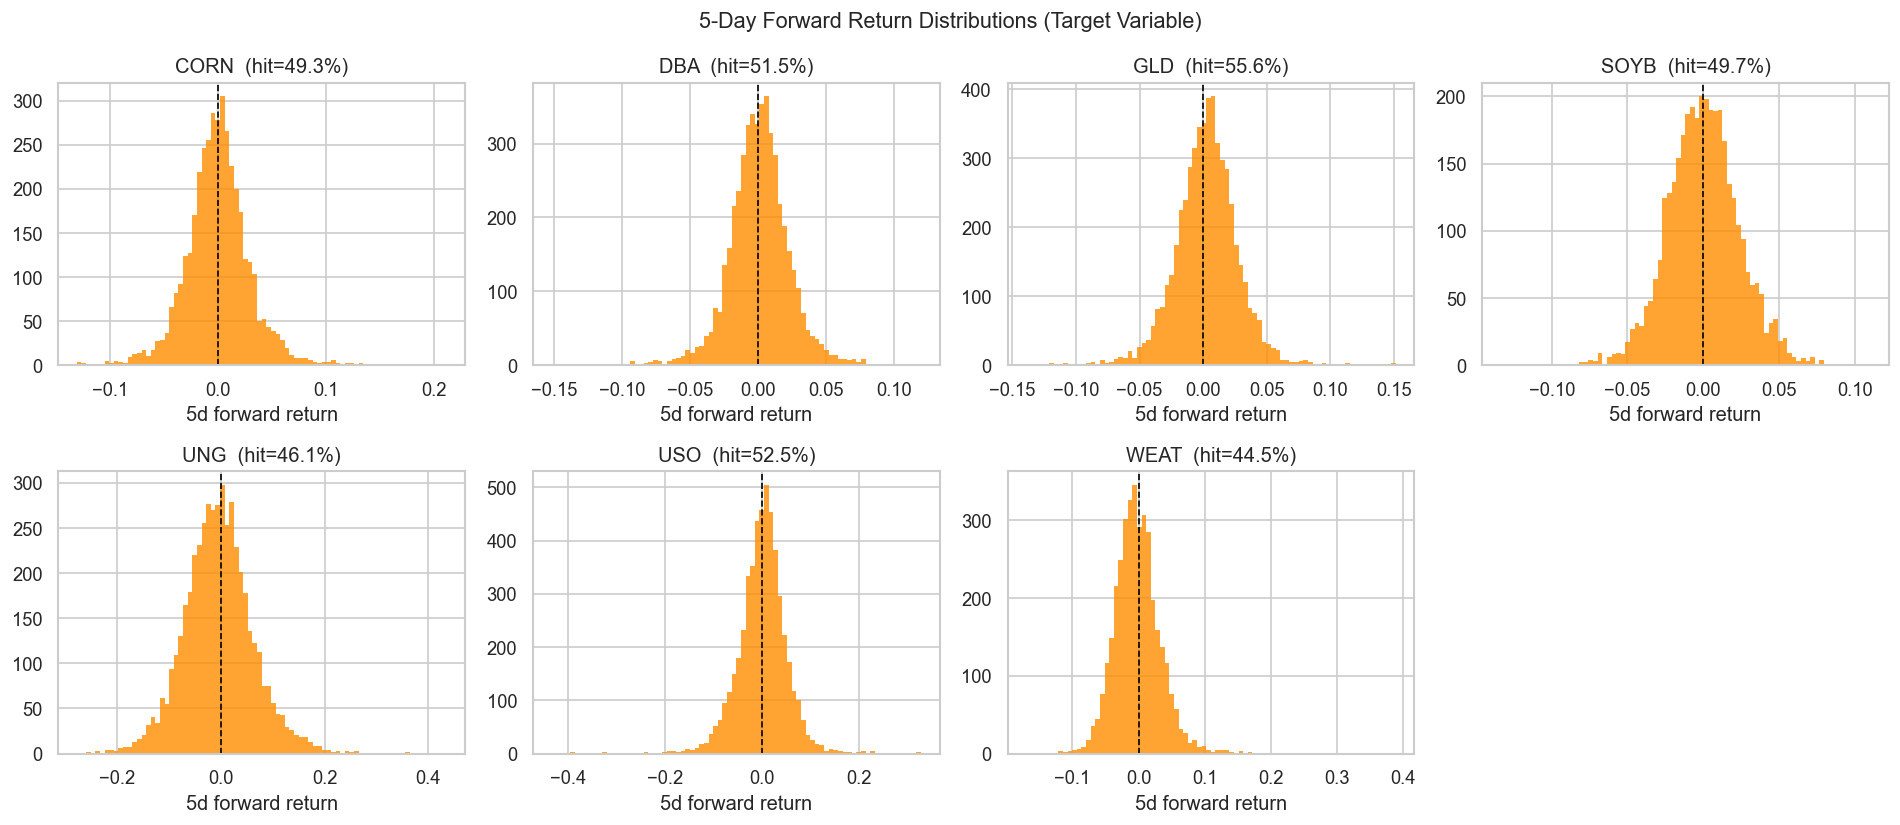

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharey=False)
axes = axes.flatten()

for i, tkr in enumerate(tickers):
    sub = df[df["ticker"] == tkr]["future_return_5d"].dropna()
    ax = axes[i]
    ax.hist(sub, bins=80, color="darkorange", edgecolor="none", alpha=0.8)
    ax.axvline(0, color="black", lw=1, ls="--")
    hit = (sub > 0).mean()
    ax.set_title(f"{tkr}  (hit={hit:.1%})")
    ax.set_xlabel("5d forward return")

for j in range(len(tickers), len(axes)):
    axes[j].set_visible(False)

fig.suptitle("5-Day Forward Return Distributions (Target Variable)", fontsize=13)
plt.tight_layout()
plt.show()

## 8. Momentum vs forward return — visual leakage check

A simple scatter of `momentum_20d` vs `future_return_5d`.  
If the correlation were too high or visually obvious, it would suggest potential leakage or that price features alone are sufficient — setting the baseline for what climate features must beat.

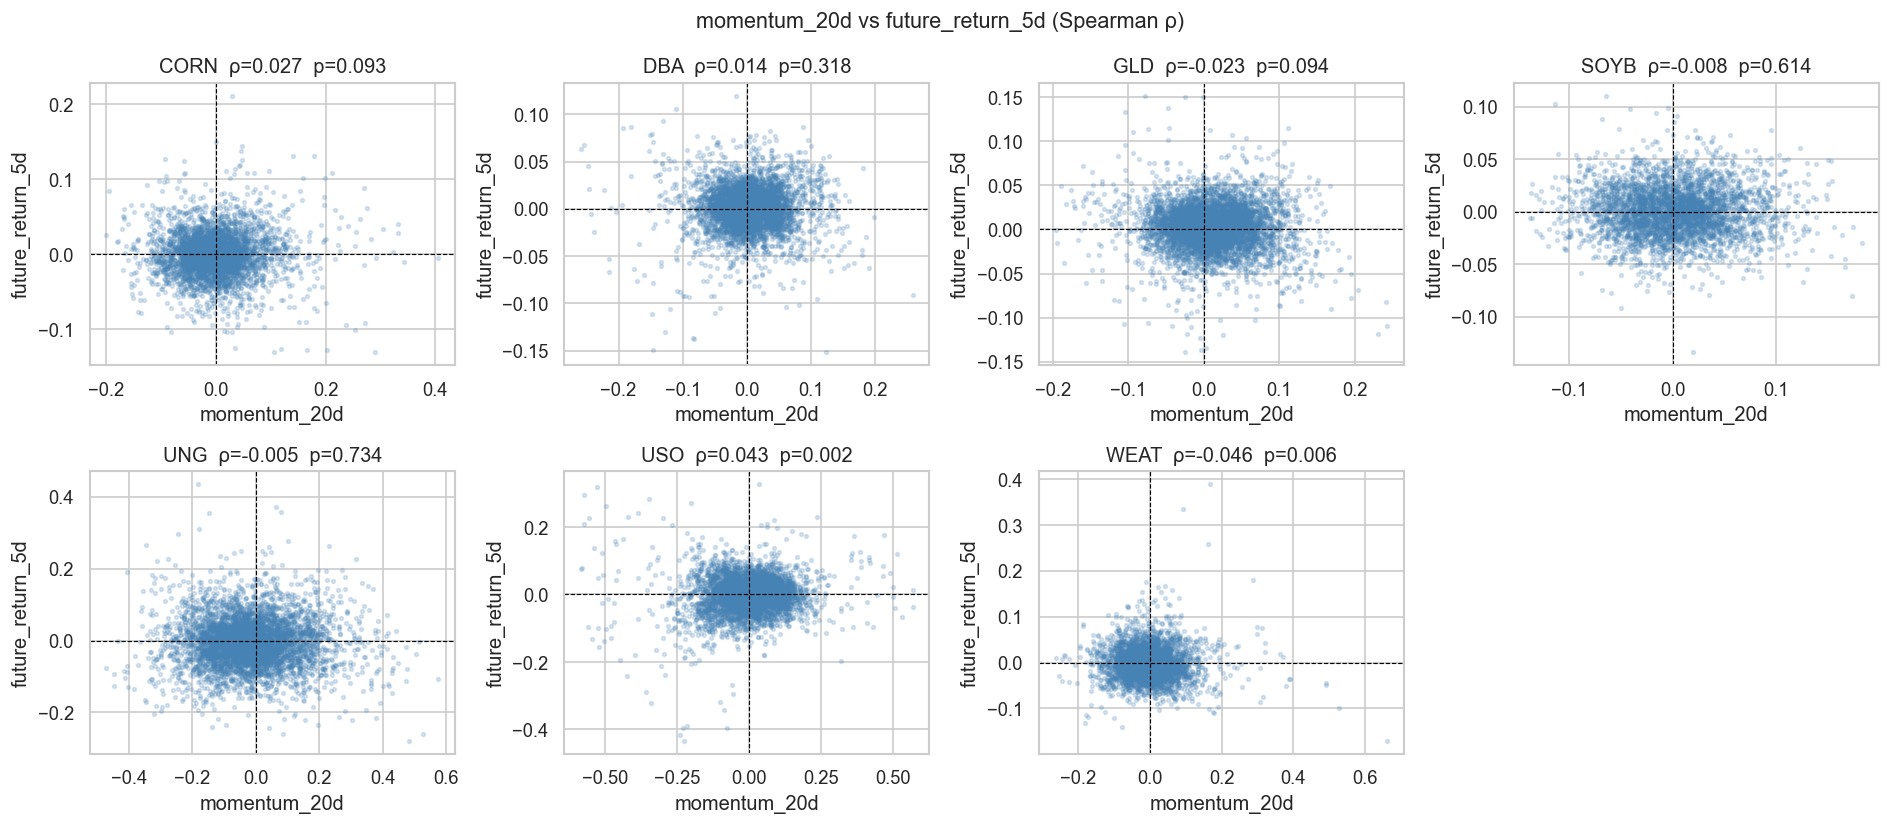

In [10]:
from scipy.stats import spearmanr

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()

for i, tkr in enumerate(tickers):
    sub = df[df["ticker"] == tkr][["momentum_20d", "future_return_5d"]].dropna()
    ax = axes[i]
    ax.scatter(sub["momentum_20d"], sub["future_return_5d"], alpha=0.2, s=5, color="steelblue")
    rho, pval = spearmanr(sub["momentum_20d"], sub["future_return_5d"])
    ax.set_title(f"{tkr}  ρ={rho:.3f}  p={pval:.3f}")
    ax.set_xlabel("momentum_20d")
    ax.set_ylabel("future_return_5d")
    ax.axhline(0, color="black", lw=0.7, ls="--")
    ax.axvline(0, color="black", lw=0.7, ls="--")

for j in range(len(tickers), len(axes)):
    axes[j].set_visible(False)

fig.suptitle("momentum_20d vs future_return_5d (Spearman ρ)", fontsize=13)
plt.tight_layout()
plt.show()

## 9. Observations

- **Volatility clusters clearly** around crisis periods (2008, 2020, 2022 energy crisis). This motivates regime-conditioned modeling in notebook 07.
- **Return correlations** between agricultural ETFs (CORN, WEAT, SOYB, DBA) are moderate-to-high (0.4–0.7). Energy (UNG, USO) and gold (GLD) form a separate cluster.
- **Momentum IC (Spearman ρ)** against 5-day forward returns is near zero for most assets — confirming that price momentum alone is a weak signal. This is the baseline that climate features need to beat or complement.
- **Target distribution** is approximately symmetric with fat tails — consistent with commodity return stylized facts. Directional hit rates hover around 51–53%, reflecting the difficulty of the prediction task.

**Next:** Notebook 02 builds weather anomaly features from NOAA data and computes rolling climate variables.